In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("feature_score_sort.csv")

In [6]:
df

,score_lgb,score_xgb,score_linreg,mean,total
0,1.000000,1.000000,5.235172e-15,6.666667e-01,9.000000e-01
1,0.914110,0.991150,1.927476e-15,6.350868e-01,8.496631e-01
2,0.886219,0.805310,1.562314e-01,6.159200e-01,7.849020e-01
3,0.872703,0.765487,9.858095e-02,5.789234e-01,7.577649e-01
4,0.731960,0.902655,1.077619e-01,5.807923e-01,7.292835e-01
...,...,...,...,...,...
74,0.000000,0.000000,9.333563e-14,3.111188e-14,9.333563e-15
75,0.000000,0.000000,3.817827e-14,1.272609e-14,3.817827e-15
76,0.000000,0.000000,1.000498e-14,3.334995e-15,1.000498e-15
77,0.000000,0.000000,4.777587e-15,1.592529e-15,4.777587e-16


In [22]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
df = pd.read_csv("feature_score_sort.csv")

# Create the Min-Max Scaler
normalizer=MinMaxScaler()

# Normalize all features
normalized_data=normalizer.fit_transform(df)

# Convert the result into a DataFrame
normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)
print("\nNormalized Dataset:")
print(normalized_df.round(2))


Normalized Dataset:
    score_lgb  score_xgb  score_linreg  mean  total
0        1.00       1.00          0.00  1.00   1.00
1        0.91       0.99          0.00  0.95   0.94
2        0.89       0.81          0.16  0.92   0.87
3        0.87       0.77          0.10  0.87   0.84
4        0.73       0.90          0.11  0.87   0.81
..        ...        ...           ...   ...    ...
74       0.00       0.00          0.00  0.00   0.00
75       0.00       0.00          0.00  0.00   0.00
76       0.00       0.00          0.00  0.00   0.00
77       0.00       0.00          0.00  0.00   0.00
78       0.00       0.00          0.00  0.00   0.00

[79 rows x 5 columns]


In [9]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 11.1 MB/s  0:00:00 11.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 11.5 MB/s  0:00:011.7 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn]0m 4/5 [scikit-learn]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:
# Create the Standard Scaler
scaler = StandardScaler()

# Standardize all features
standardized_data=scaler.fit_transform(df)

# Convert the result into a DataFrrame
standardized_df=pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("\nStandardized Dataset:")
print(standardized_df.round(2))

print("\nMean of standardized features:")
print(standardized_df.mean().round(2))

print("\nStandard deviation of standardized features:")
print(standardized_df.std(ddof=0).round(2))


Standardized Dataset:
    score_lgb  score_xgb  score_linreg  mean  total
0        3.24       3.27         -0.26  3.02   3.24
1        2.90       3.24         -0.26  2.84   3.01
2        2.79       2.49          0.71  2.73   2.73
3        2.73       2.34          0.35  2.52   2.61
4        2.17       2.88          0.41  2.53   2.48
..        ...        ...           ...   ...    ...
74      -0.75      -0.72         -0.26 -0.78  -0.76
75      -0.75      -0.72         -0.26 -0.78  -0.76
76      -0.75      -0.72         -0.26 -0.78  -0.76
77      -0.75      -0.72         -0.26 -0.78  -0.76
78      -0.75      -0.72         -0.26 -0.78  -0.76

[79 rows x 5 columns]

Mean of standardized features:
score_lgb       0.0
score_xgb       0.0
score_linreg   -0.0
mean           -0.0
total           0.0
dtype: float64

Standard deviation of standardized features:
score_lgb       1.0
score_xgb       1.0
score_linreg    1.0
mean            1.0
total           1.0
dtype: float64


In [24]:
# Standard the data before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Create PCA with two components
pca = PCA(n_components=2)

# Transform the standardized data
pca_data = pca.fit_transform(X_scaled)

# Store the results in a DataFrame
pca_df = pd.DataFrame(pca_data,
        columns = ['Principal_Component_1','Principal_Component_2'])

print("\nPCA Transformed Dataset:")
print(pca_df.round(2))

# Display explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum()*100,2),"%")


PCA Transformed Dataset:
    Principal_Component_1  Principal_Component_2
0                    6.35                  -0.78
1                    5.95                  -0.75
2                    5.41                   0.30
3                    5.11                  -0.05
4                    5.05                   0.01
..                    ...                    ...
74                  -1.52                  -0.15
75                  -1.52                  -0.15
76                  -1.52                  -0.15
77                  -1.52                  -0.15
78                  -1.52                  -0.15

[79 rows x 2 columns]

Explained Variance Ratio:
[0.7867 0.2092]

Total Variance Retained:
99.59 %


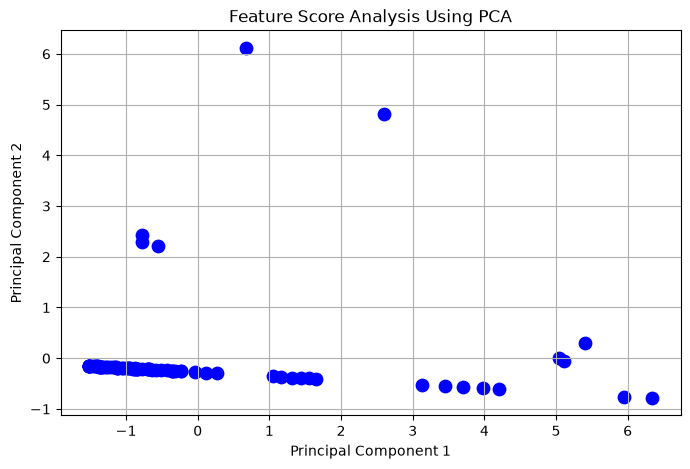

In [20]:
plt.figure(figsize=(8,5))
plt.scatter(
    pca_df['Principal_Component_1'],
    pca_df['Principal_Component_2'],
    color = 'blue',
    s = 80
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Feature Score Analysis Using PCA')
plt.grid(True)
plt.show()

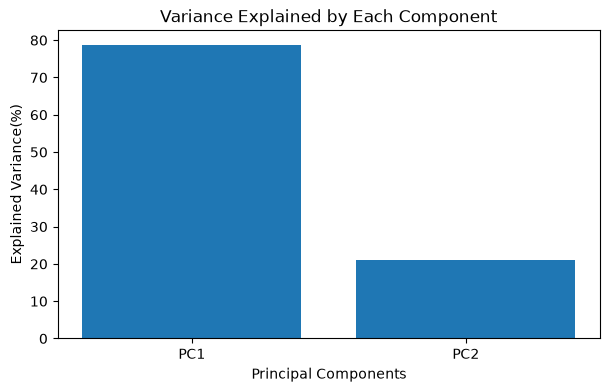

In [21]:
plt.figure(figsize=(7,4))
components = ['PC1','PC2']
plt.bar(
    components,
    pca.explained_variance_ratio_*100)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance(%)')
plt.title('Variance Explained by Each Component')
plt.show()